<a href="https://colab.research.google.com/github/samuel1599gt/actividad2/blob/main/Actividad3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad 3 - Métodos de aprendizaje supervisado

In [6]:

# Importación de librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Modelo de aprendizaje supervisado
from sklearn.linear_model import LinearRegression

# Importar y conectar Google Drive
from google.colab import drive
drive.mount('/content/drive')



Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:

# Leer archivo Excel desde Google Drive
datos = pd.read_excel('/content/drive/MyDrive/dataset_transporte_publico_120_registros.xlsx')

# Mostrar los primeros registros
print(datos.head())


   distancia_km  tiempo_minutos  combustible_litros
0          3.94              10               0.255
1          2.36               5               0.145
2          4.34              17               0.284
3          3.58              11               0.228
4          0.74               2               0.035


In [5]:

# Importar la herramienta de normalización
from sklearn.preprocessing import MinMaxScaler

# Crear el normalizador
escalador = MinMaxScaler()

# Normalizar los datos
datos_normalizados = pd.DataFrame(
    escalador.fit_transform(datos),
    columns=datos.columns
)

# Mostrar los datos normalizados
print(datos_normalizados.head())


   distancia_km  tiempo_minutos  combustible_litros
0      0.791667        0.473684            0.770492
1      0.445175        0.210526            0.409836
2      0.879386        0.842105            0.865574
3      0.712719        0.526316            0.681967
4      0.089912        0.052632            0.049180


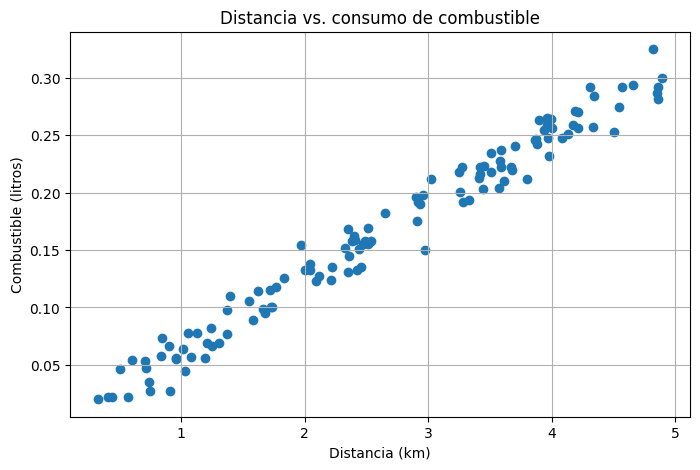

In [7]:
plt.figure(figsize=(8, 5))
plt.scatter(datos["distancia_km"], datos["combustible_litros"])
plt.title("Distancia vs. consumo de combustible")
plt.xlabel("Distancia (km)")
plt.ylabel("Combustible (litros)")
plt.grid(True)
plt.show()


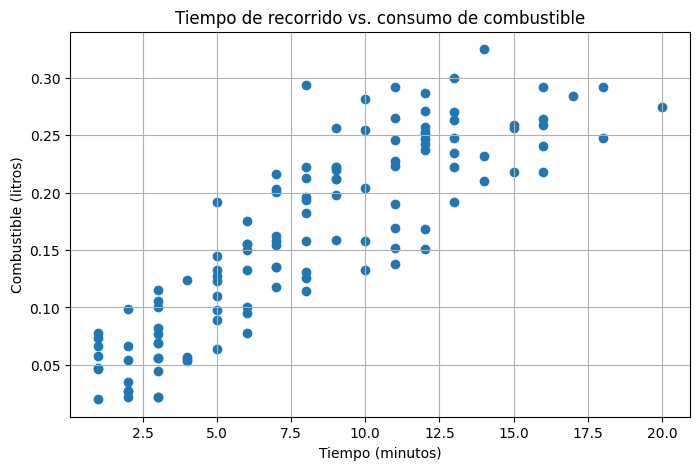

In [8]:
plt.figure(figsize=(8, 5))
plt.scatter(datos["tiempo_minutos"], datos["combustible_litros"])
plt.title("Tiempo de recorrido vs. consumo de combustible")
plt.xlabel("Tiempo (minutos)")
plt.ylabel("Combustible (litros)")
plt.grid(True)
plt.show()

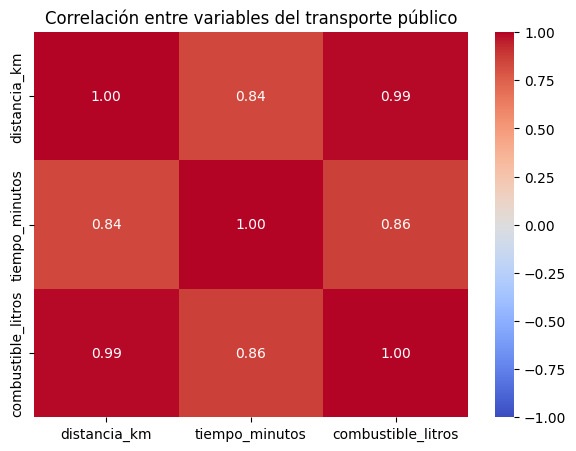

In [9]:
correlacion = datos.corr(numeric_only=True)

plt.figure(figsize=(7, 5))
sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".2f"
)
plt.title("Correlación entre variables del transporte público")
plt.show()

In [10]:

# Importar librerías
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Definir las variables
X = datos[["distancia_km", "tiempo_minutos"]]
y = datos["combustible_litros"]

# 2. Dividir los datos: 80% entrenamiento y 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# 3. Crear el modelo
modelo = LinearRegression()

# 4. Entrenar el modelo
modelo.fit(X_train, y_train)

# 5. Realizar predicciones sobre los datos de prueba
predicciones = modelo.predict(X_test)

# 6. Evaluar el modelo
mae = mean_absolute_error(y_test, predicciones)
rmse = np.sqrt(mean_squared_error(y_test, predicciones))
r2 = r2_score(y_test, predicciones)

print("===== RESULTADOS DEL MODELO =====")
print(f"Registros de entrenamiento: {len(X_train)}")
print(f"Registros de prueba: {len(X_test)}")
print(f"Error absoluto medio (MAE): {mae:.4f} litros")
print(f"Raíz del error cuadrático medio (RMSE): {rmse:.4f} litros")
print(f"Coeficiente R²: {r2:.4f}")


===== RESULTADOS DEL MODELO =====
Registros de entrenamiento: 96
Registros de prueba: 24
Error absoluto medio (MAE): 0.0114 litros
Raíz del error cuadrático medio (RMSE): 0.0134 litros
Coeficiente R²: 0.9735


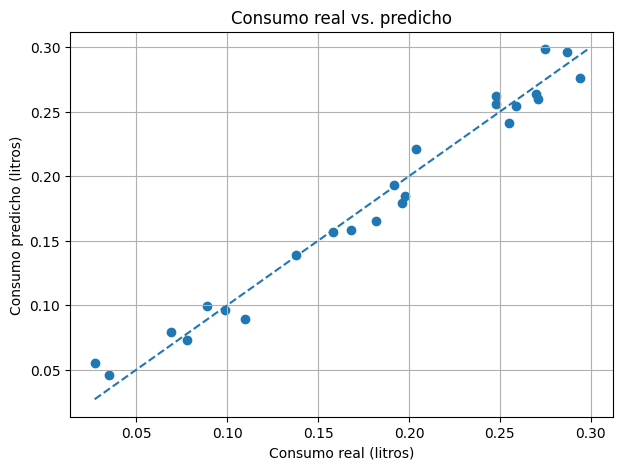

In [11]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predicciones)

limite_min = min(y_test.min(), predicciones.min())
limite_max = max(y_test.max(), predicciones.max())

plt.plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--"
)

plt.xlabel("Consumo real (litros)")
plt.ylabel("Consumo predicho (litros)")
plt.title("Consumo real vs. predicho")
plt.grid(True)
plt.show()